# Bài thực hành kiểm toán mô hình — S&P 500

**Bài kiểm tra mù được thiết kế để giảng viên kiểm tra quy trình đánh giá.** Hai quy trình A/B ở dưới là các ca thực hành, có thể chứa lỗi chủ ý. Điểm số chưa được coi là bằng chứng về năng lực dự báo trước khi kiểm toán. Đáp án được giữ ở tệp riêng.

## Nhiệm vụ
1. Xác định thông tin nào được phép tồn tại tại thời điểm dự báo.
2. Kiểm tra quan hệ giữa các tập fit, validation và test ở cả cấp ngày lẫn khoảng thời gian nhãn.
3. Giải thích chênh lệch điểm A/B bằng bằng chứng trong pipeline; không chỉ đoán từ điểm số.
4. Đề xuất kiểm tra tự động để phát hiện lỗi và một protocol đánh giá đúng.

Dữ liệu mặc định: S&P 500 thật từ 03/01/2000 đến 17/04/2020; không phải thị trường hiện tại. Cả hai ca dùng cùng đặc trưng, mục tiêu và cấu hình mô hình. Không sửa các giá trị metric tính từ dự báo.

In [1]:
# Cài thư viện trong môi trường riêng trước khi chạy, không pip install giữa notebook.
import os, io, json, time, hashlib, random, copy, platform
from pathlib import Path
from datetime import date, timedelta
from urllib.request import urlopen
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, roc_auc_score, brier_score_loss,
    confusion_matrix, RocCurveDisplay)
from sklearn.calibration import calibration_curve
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 14)
versions = {name: metadata.version(name) for name in
            ['numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn', 'scikit-learn', 'torch']}
display(pd.Series({'Python': platform.python_version(), **versions}, name='Phiên bản').to_frame())

,Phiên bản
Python,3.12.14
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2
scikit-learn,1.9.1
torch,2.15.0+cpu


In [2]:
DATA_SOURCE = os.environ.get('SP500_DATA_SOURCE', 'historical_sample')
CSV_PATH = Path(os.environ.get('SP500_CSV', 'sp500_historical.csv'))
START_DATE = '2000-01-01'
END_DATE = (date.today() + timedelta(days=1)).isoformat()  # Yahoo: ngày kết thúc loại trừ
H = 5                  # số phiên tương lai của mục tiêu rủi ro
ANNUAL = 252
RUN_MLP = True
ARTIFACT_DIR = Path(os.environ.get('SP500_OUTPUT_DIR', 'outputs/audit_exercise'))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_URL = ('https://raw.githubusercontent.com/vega/vega-datasets/'
              '5448e25297c8f705be78e879d5423d55d04dc6f1/data/sp500-2000.csv')
SAMPLE_SHA256 = '9409e9342d0657c747324e4cfabce8a8c7f663bc485b95a3378f36b0a160f8c8'
CACHE_PATH = ARTIFACT_DIR / 'sp500-2000.csv'


def read_price_csv(path_or_buffer):
    """Phát hiện CSV yfinance MultiIndex trước khi chuẩn hóa tên cột."""
    if isinstance(path_or_buffer, (str, Path)):
        raw = Path(path_or_buffer).read_bytes()
    else:
        raw = path_or_buffer.read()
    lines = raw.decode('utf-8-sig').splitlines()
    if len(lines) > 1 and lines[1].split(',')[0] == 'Ticker':
        frame = pd.read_csv(io.BytesIO(raw), header=[0, 1], index_col=0)
        tickers = set(frame.columns.get_level_values(1))
        if len(tickers) != 1:
            raise ValueError('CSV có nhiều mã. Hãy xuất riêng một chỉ số S&P 500.')
        frame.columns = frame.columns.get_level_values(0)
        frame.index = pd.to_datetime(frame.index, errors='raise')
        frame.index.name = 'Date'
        return frame.reset_index()
    return pd.read_csv(io.BytesIO(raw))


if DATA_SOURCE == 'historical_sample':
    payload = CACHE_PATH.read_bytes() if CACHE_PATH.exists() else urlopen(SAMPLE_URL, timeout=30).read()
    if hashlib.sha256(payload).hexdigest() != SAMPLE_SHA256:
        raise ValueError('Checksum dữ liệu mẫu không khớp. Không sử dụng dữ liệu chưa xác minh.')
    CACHE_PATH.write_bytes(payload)
    raw_data = read_price_csv(io.BytesIO(payload))
    provenance = {'source': DATA_SOURCE, 'url': SAMPLE_URL, 'sha256': SAMPLE_SHA256}
elif DATA_SOURCE == 'csv':
    raw_data = read_price_csv(CSV_PATH)
    provenance = {'source': 'csv', 'path': str(CSV_PATH),
                  'sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()}
elif DATA_SOURCE == 'yahoo':
    import yfinance as yf
    downloaded = yf.download('^GSPC', start=START_DATE, end=END_DATE,
                             auto_adjust=False, progress=False, threads=False, timeout=20)
    if downloaded.empty:
        raise RuntimeError('Yahoo trả dữ liệu rỗng. Kiểm tra mạng hoặc chọn CSV; không dùng kết quả rỗng.')
    if isinstance(downloaded.columns, pd.MultiIndex):
        downloaded.columns = downloaded.columns.get_level_values(0)
    raw_data = downloaded.reset_index()
    provenance = {'source': 'yahoo', 'ticker': '^GSPC', 'start_requested': START_DATE,
                  'end_exclusive': END_DATE, 'yfinance_version': metadata.version('yfinance')}
else:
    raise ValueError('DATA_SOURCE phải là historical_sample, csv hoặc yahoo.')
print('Nguồn dữ liệu:', provenance['source'])
display(raw_data.head())

Nguồn dữ liệu: historical_sample


,date,open,high,low,close,adjclose,volume
0,2000-01-03,1469.250000,1478.000000,1438.359985,1455.219971,1455.219971,931800000
1,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,1399.420044,1009000000
2,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,1402.109985,1085500000
3,2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,1403.449951,1092300000
4,2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,1441.469971,1225200000


In [3]:
# Chuẩn hóa và kiểm tra dữ liệu; không forward-fill giá trong ngày bị thiếu.
rename = {str(c): str(c).strip().lower().replace(' ', '_') for c in raw_data.columns}
prices = raw_data.rename(columns=rename).copy()
if 'date' not in prices.columns or 'close' not in prices.columns:
    raise ValueError('Cần cột Date và Close (không phân biệt hoa/thường).')
prices['date'] = pd.to_datetime(prices['date'], errors='raise', utc=True).dt.tz_convert(None).dt.normalize()
prices = prices.set_index('date').sort_index()
if prices.index.has_duplicates:
    raise ValueError('Ngày bị trùng: kiểm tra nguồn thay vì tự ý bỏ bản ghi.')
for column in prices.columns:
    prices[column] = pd.to_numeric(prices[column], errors='raise')
if prices['close'].isna().any() or (prices['close'] <= 0).any():
    raise ValueError('Close thiếu, bằng 0 hoặc âm. Cần sửa dữ liệu nguồn.')
if not np.isfinite(prices['close']).all():
    raise ValueError('Close có giá trị vô hạn.')
if len(prices) < 1000:
    raise ValueError('Cần ít nhất 1.000 phiên để chia tập, xem chế độ thị trường và đánh giá mô hình.')
median_gap = prices.index.to_series().diff().dt.days.median()
if median_gap > 3:
    raise ValueError('Dữ liệu có vẻ không phải theo ngày. Không áp dụng quy năm 252 cho dữ liệu tháng.')
if {'high', 'low', 'open'}.issubset(prices.columns):
    bad_ohlc = (prices['high'] < prices[['open', 'close', 'low']].max(axis=1)) | (prices['low'] > prices[['open', 'close', 'high']].min(axis=1))
    if bad_ohlc.any():
        raise ValueError(f'Có {bad_ohlc.sum()} dòng OHLC không nhất quán.')
returns = prices['close'].pct_change(fill_method=None)
log_returns = np.log(prices['close']).diff()
provenance.update({'first_date': str(prices.index.min().date()),
                   'last_date': str(prices.index.max().date()), 'rows': len(prices)})
if DATA_SOURCE == 'yahoo':
    provenance['normalized_csv_sha256'] = hashlib.sha256(prices.to_csv().encode()).hexdigest()
    prices.to_csv(ARTIFACT_DIR / 'downloaded_prices.csv')
(ARTIFACT_DIR / 'data_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
quality = pd.DataFrame({
    'Chỉ tiêu': ['Phiên', 'Từ ngày', 'Đến ngày', 'Ngày trùng', 'Close thiếu',
                 'Khoảng cách lịch lớn nhất (ngày)', 'Phiên |lợi suất| > 10%'],
    'Giá trị': [len(prices), provenance['first_date'], provenance['last_date'],
               int(prices.index.duplicated().sum()), int(prices.close.isna().sum()),
               int(prices.index.to_series().diff().dt.days.max()), int((returns.abs() > .10).sum())]})
display(quality)
display(prices.describe().T.round(3))
print('Khoảng cách lịch có thể gồm cuối tuần/ngày nghỉ; không mặc định đó là dữ liệu bị mất.')
print('Các phiên cực đoan được giữ lại. Không winsorize toàn bộ dữ liệu trước khi chia tập.')

,Chỉ tiêu,Giá trị
0,Phiên,5105
1,Từ ngày,2000-01-03
2,Đến ngày,2020-04-17
3,Ngày trùng,0
4,Close thiếu,0
5,Khoảng cách lịch lớn nhất (ngày),7
6,Phiên |lợi suất| > 10%,3


,count,mean,std,min,25%,50%,75%,max
open,5105.0,1.595460e+03,6.073870e+02,6.792800e+02,1.155430e+03,1.367090e+03,2.015270e+03,3.380450e+03
high,5105.0,1.604680e+03,6.087060e+02,6.952700e+02,1.163750e+03,1.376510e+03,2.023770e+03,3.393520e+03
low,5105.0,1.585437e+03,6.058210e+02,6.667900e+02,1.144780e+03,1.358690e+03,2.002330e+03,3.378830e+03
close,5105.0,1.595641e+03,6.074780e+02,6.765300e+02,1.155460e+03,1.367340e+03,2.016710e+03,3.386150e+03
adjclose,5105.0,1.595641e+03,6.074780e+02,6.765300e+02,1.155460e+03,1.367340e+03,2.016710e+03,3.386150e+03
volume,5105.0,3.124407e+09,1.503512e+09,3.560700e+08,1.692000e+09,3.235340e+09,3.931120e+09,1.145623e+10


Khoảng cách lịch có thể gồm cuối tuần/ngày nghỉ; không mặc định đó là dữ liệu bị mất.
Các phiên cực đoan được giữ lại. Không winsorize toàn bộ dữ liệu trước khi chia tập.


## Đặc trưng và mục tiêu
Dự báo RMS lợi suất của 5 phiên tiếp theo, quy năm theo 252 phiên. Đặc trưng chỉ sử dụng dữ liệu đã có đến cuối phiên hôm nay. Hãy kiểm tra cả việc tạo nhãn và cách đưa các dòng vào mô hình ở các ô tiếp theo.

In [4]:
def build_features(frame, horizon=5):
    c = frame['close']
    ret = c.pct_change(fill_method=None)
    X = pd.DataFrame(index=frame.index)
    X['return_1'] = ret
    X['abs_return_1'] = ret.abs()
    X['negative_return_1'] = ret.clip(upper=0)
    for window in [5, 10, 22, 66]:
        X[f'rv_{window}'] = ret.pow(2).rolling(window).mean().mul(ANNUAL).pow(.5)
    X['ewma_94'] = ret.pow(2).ewm(alpha=.06, adjust=False, min_periods=22).mean().mul(ANNUAL).pow(.5)
    for window in [5, 22, 66]:
        X[f'momentum_{window}'] = c.pct_change(window, fill_method=None)
    X['distance_ma22'] = c / c.rolling(22).mean() - 1
    X['drawdown_252'] = c / c.rolling(252, min_periods=66).max() - 1
    gain = ret.clip(lower=0).rolling(14).mean()
    loss = (-ret.clip(upper=0)).rolling(14).mean()
    X['rsi_14'] = 100 * gain / (gain + loss).replace(0, np.nan)
    X['rv_short_long'] = X['rv_5'] / X['rv_22']
    if {'high', 'low'}.issubset(frame.columns):
        X['range_1'] = np.log(frame['high'] / frame['low'])
        X['range_mean_5'] = X['range_1'].rolling(5).mean()
    future_rv = ret.pow(2).rolling(horizon).mean().shift(-horizon).mul(ANNUAL).pow(.5)
    next_ret = ret.shift(-1)
    direction = (next_ret > 0).astype(float).where(next_ret.notna())
    return X.replace([np.inf, -np.inf], np.nan), future_rv.rename('future_rv'), direction.rename('up_next')

X_all, y_all, y_direction_all = build_features(prices, H)
valid = X_all.notna().all(axis=1) & y_all.notna() & (y_all > 0) & y_direction_all.notna()
X = X_all.loc[valid].copy()
y = y_all.loc[valid].copy()
y_direction = y_direction_all.loc[valid].astype(int)
label_end = pd.Series(prices.index, index=prices.index).shift(-H).loc[X.index]

# Kiểm tra ý nghĩa nhãn và việc giữ thiếu ở biên tương lai.
assert y_all.iloc[-H:].isna().all()
assert pd.isna(y_direction_all.iloc[-1])
check_date = X.index[100]
pos = prices.index.get_loc(check_date)
expected = np.sqrt(ANNUAL * returns.iloc[pos+1:pos+H+1].pow(2).mean())
assert np.isclose(y.loc[check_date], expected)
# Thay giá tương lai không được làm thay đổi đặc trưng quá khứ.
cutoff = len(prices) // 2
changed = prices.copy()
changed.loc[changed.index[cutoff+1]:, 'close'] *= 1.1
changed_features, _, _ = build_features(changed, H)
pd.testing.assert_frame_equal(X_all.iloc[:cutoff+1], changed_features.iloc[:cutoff+1])
print(f'{len(X):,} mẫu có nhãn; {X.shape[1]} đặc trưng; kiểm tra nhãn và tính nhân quả: PASS.')
display(X.join(y).head().round(4))

5,034 mẫu có nhãn; 17 đặc trưng; kiểm tra nhãn và tính nhân quả: PASS.


,return_1,abs_return_1,negative_return_1,rv_5,rv_10,rv_22,rv_66,...,distance_ma22,drawdown_252,rsi_14,rv_short_long,range_1,range_mean_5,future_rv
date,,,,,,,,,,,,,,,
2000-04-06,0.0094,0.0094,0.0000,0.1109,0.1175,0.2526,0.2392,...,0.0244,-0.0171,61.2152,0.4389,0.0163,0.0295,0.2239
2000-04-07,0.0100,0.0100,0.0000,0.1214,0.1278,0.2533,0.2280,...,0.0298,-0.0073,67.2294,0.4793,0.0115,0.0270,0.4650
2000-04-10,-0.0078,0.0078,-0.0078,0.1289,0.1332,0.2395,0.2285,...,0.0185,-0.0151,53.7468,0.5381,0.0157,0.0275,0.5180
2000-04-11,-0.0026,0.0026,-0.0026,0.1189,0.1228,0.2391,0.2285,...,0.0126,-0.0176,50.2428,0.4972,0.0173,0.0160,0.5562
2000-04-12,-0.0223,0.0223,-0.0223,0.1947,0.1661,0.2492,0.2265,...,-0.0125,-0.0395,30.9217,0.7814,0.0289,0.0179,0.5378


In [5]:
n = len(X)
a, b = int(n * .70), int(n * .85)
train_idx = np.arange(0, a-H)
val_idx = np.arange(a, b-H)
test_idx = np.arange(b, n)
dev_idx = np.arange(0, b-H)

rng = np.random.default_rng(SEED)
extra_v = rng.choice(val_idx, size=int(.25 * len(val_idx)), replace=False)
extra_t = rng.choice(test_idx, size=int(.40 * len(test_idx)), replace=False)
protocols = {
    'A': {'fit_validation': np.sort(np.r_[train_idx, extra_v, extra_t]),
          'fit_test': np.sort(np.r_[dev_idx, extra_t])},
    'B': {'fit_validation': train_idx, 'fit_test': dev_idx},
}
print('Validation:', len(val_idx), 'mẫu; test:', len(test_idx), 'mẫu.')
print('Cấu hình mô hình và tập đánh giá giống nhau giữa các ca.')

Validation: 750 mẫu; test: 756 mẫu.
Cấu hình mô hình và tập đánh giá giống nhau giữa các ca.


## Chạy hai quy trình

Không xóa điểm ngoại lệ hoặc sửa thủ công kết quả. Mỗi quy trình dùng cùng một ExtraTrees và cùng ngưỡng phân loại 0.5. Điểm cao hơn là quan sát cần giải thích, chưa phải kết luận mô hình tốt hơn.

In [6]:
from sklearn.ensemble import ExtraTreesClassifier


def metrics_reg(actual, predicted):
    return {'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
            'MAE': float(mean_absolute_error(actual, predicted)),
            'R2': float(r2_score(actual, predicted))}


def metrics_cls(actual, probability):
    return {'Accuracy': float(accuracy_score(actual, probability >= .5)),
            'Balanced accuracy': float(balanced_accuracy_score(actual, probability >= .5)),
            'AUC': float(roc_auc_score(actual, probability)),
            'Brier': float(brier_score_loss(actual, probability))}


reg_rows, cls_rows, all_predictions = [], [], {}
for case, splits in protocols.items():
    for stage, fitting, evaluating in [('Validation', splits['fit_validation'], val_idx),
                                        ('Test', splits['fit_test'], test_idx)]:
        reg = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=1,
                                  random_state=SEED, n_jobs=2)
        reg.fit(X.iloc[fitting], np.log(y.iloc[fitting]))
        prediction = np.exp(reg.predict(X.iloc[evaluating]))
        clf = ExtraTreesClassifier(n_estimators=150, min_samples_leaf=1,
                                   random_state=SEED, n_jobs=2)
        clf.fit(X.iloc[fitting], y_direction.iloc[fitting])
        probability = clf.predict_proba(X.iloc[evaluating])[:, 1]
        reg_rows.append({'Case': case, 'Stage': stage, **metrics_reg(y.iloc[evaluating], prediction)})
        cls_rows.append({'Case': case, 'Stage': stage, **metrics_cls(y_direction.iloc[evaluating], probability)})
        all_predictions[(case, stage)] = (prediction, probability)
reg_results = pd.DataFrame(reg_rows)
cls_results = pd.DataFrame(cls_rows)
display(reg_results.round(4))
display(cls_results.round(4))

,Case,Stage,RMSE,MAE,R2
0,A,Validation,0.0407,0.0237,0.6315
1,A,Test,0.0647,0.0260,0.8417
2,B,Validation,0.0540,0.0379,0.3515
3,B,Test,0.1014,0.0524,0.6117


,Case,Stage,Accuracy,Balanced accuracy,AUC,Brier
0,A,Validation,0.6213,0.6164,0.7204,0.1946
1,A,Test,0.7116,0.7049,0.8233,0.1555
2,B,Validation,0.5013,0.4958,0.5038,0.2598
3,B,Test,0.5040,0.5053,0.5182,0.2585


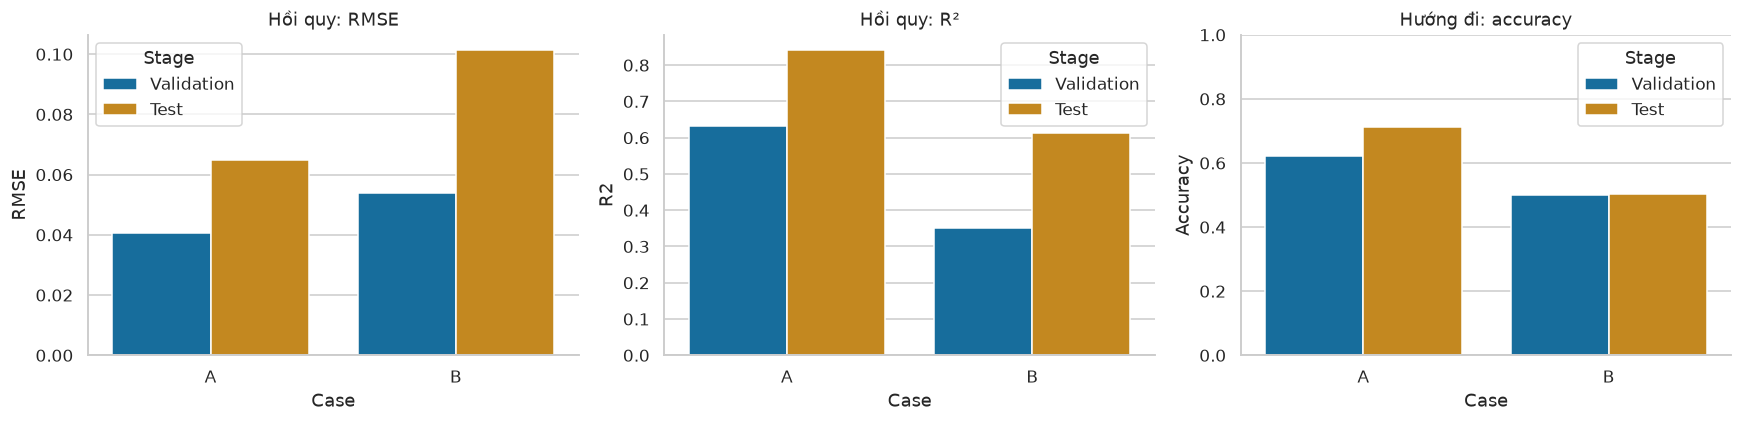

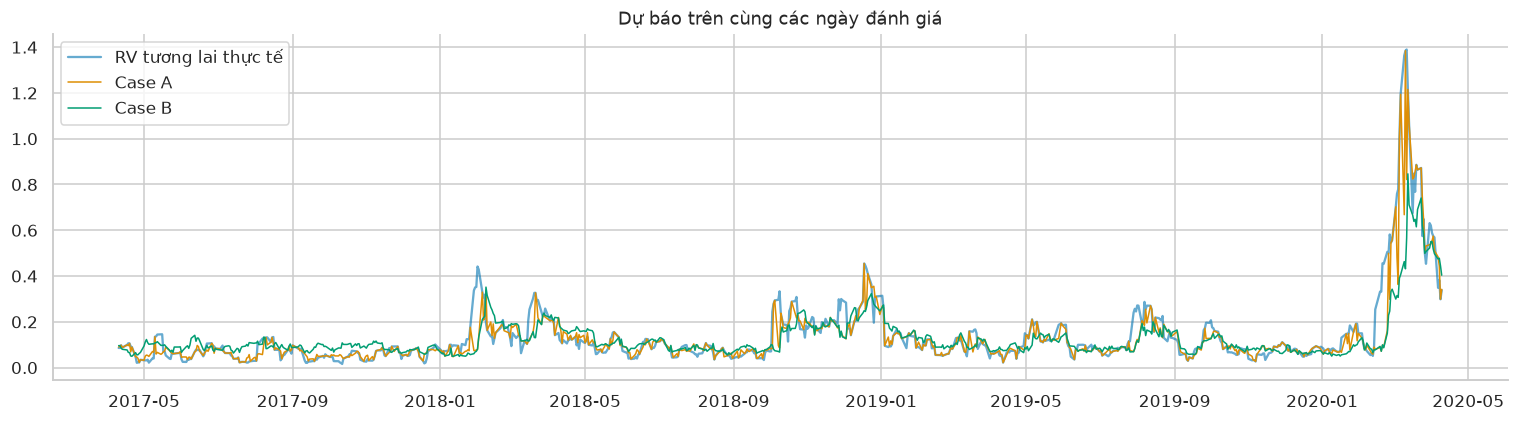

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=reg_results, x='Case', y='RMSE', hue='Stage', errorbar=None, ax=axes[0])
axes[0].set_title('Hồi quy: RMSE')
sns.barplot(data=reg_results, x='Case', y='R2', hue='Stage', errorbar=None, ax=axes[1])
axes[1].set_title('Hồi quy: R²')
sns.barplot(data=cls_results, x='Case', y='Accuracy', hue='Stage', errorbar=None, ax=axes[2])
axes[2].set(ylim=(0, 1), title='Hướng đi: accuracy')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index[test_idx], y.iloc[test_idx], label='RV tương lai thực tế', alpha=.6)
for case in protocols:
    ax.plot(y.index[test_idx], all_predictions[(case, 'Test')][0], label=f'Case {case}', lw=1)
ax.set_title('Dự báo trên cùng các ngày đánh giá'); ax.legend()
plt.tight_layout(); plt.show()

## Câu trả lời của người kiểm toán

- Quy trình nào cho phép đánh giá khả năng dự báo trên dữ liệu chưa được dùng để fit? Vì sao?
- Những dòng nào xuất hiện ở nhiều tập? Có nhãn nào vượt qua ranh giới thời gian không?
- Accuracy tăng có đồng nghĩa với dự báo hướng đi tốt hơn không?
- Những assertions nào nên đặt trước bước fit để phát hiện vấn đề?
- Sau khi sửa lỗi, cần huấn luyện và báo cáo lại những gì?

**Đây là kết quả của bài tập kiểm toán, không phải kết quả nghiên cứu để sử dụng trong báo cáo hiệu năng mô hình.**

In [8]:
reg_results.to_csv(ARTIFACT_DIR / 'audit_regression.csv', index=False)
cls_results.to_csv(ARTIFACT_DIR / 'audit_classification.csv', index=False)
print('Kết quả bài tập đã được xuất. Đối chiếu với đáp án sau khi hoàn thành kiểm toán.')

Kết quả bài tập đã được xuất. Đối chiếu với đáp án sau khi hoàn thành kiểm toán.
